# Imports

In [33]:
"""Run elasticity on the layered/faulted grid with hole."""

from pathlib import Path

from create_grid import create_layered_grid_with_hole
from common_functions import solve_and_export_pressure

#folder = Path(__file__).parent
folder = Path.cwd()



In [34]:


"""Run the layered-grid-with-hole elasticity workflow.

Parameters
----------
None
    The script uses fixed settings defined inside the function.

Returns
-------
None
    Solution files are written to the results directory.
"""
mesh_size = 0.025

# Step 1: generate layered/faulted grid with hole and layer id.
# Use function defaults for geometry, fault, and hole settings.
sd, cell_layer = create_layered_grid_with_hole(mesh_size=mesh_size, center=(1.5, 0.25))



c:\Users\steto\anaconda3.1\envs\poresct4amm2526\Lib\site-packages\porepy\grids\mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")


In [35]:


# Step 2: solve elasticity and export displacement + layer id.
folder_export = folder / "results"

#give the desired pressure and the layer ID where you want to apply it
layer_ID = 3
pressure_value = 0.5

solve_and_export_pressure(
        sd,
        cell_layer,
        layer_ID,
        pressure_value,
        folder_export,
        export_name="sol_layered_ID3",
        cell_data=[("layer", cell_layer.astype(float))],
    )



array([[-0.00635488,  0.        ,  0.        , ...,  0.06347641,
         0.01835137,  0.07270313],
       [-0.0133904 ,  0.        ,  0.        , ..., -0.02008315,
         0.01390767, -0.00288462],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ]], shape=(3, 6256))

# Signature of the function

In [36]:
def GroupSolutionCP2( layer_ID , pressure_value, center_location_mean, center_location_std ):

    # your implementation

    # format of the output (as a function)
    # surface_displacement 
    #CI_corner = [(0.1,0.2),(0.15,0.25)]

    return mean_surface_displacement, CI_corner

In [37]:
import numpy as np
import shutil
from pathlib import Path
from scipy.interpolate import interp1d

# Assicurati di importare le tue funzioni base
from create_grid import create_layered_grid_with_hole
from common_functions import solve_and_export_pressure

def run_fem(center, layer_ID, pressure_value, mesh_size=0.025):
    """
    Esegue una simulazione FEM diretta (Fisica Reale) e restituisce 
    il profilo di spostamento superficiale e i valori all'angolo.
    """
    # 1. Creazione della griglia e assegnazione dei layer (QUI AGGIUNGIAMO IL BUCO PICCOLO)
    sd, cell_layer = create_layered_grid_with_hole(
        mesh_size=mesh_size, 
        center=center,
        axes=(0.1, 0.05) # <-- FONDAMENTALE: stessa dimensione del training!
    )
    
    # IMPORTANTE: calcolo della geometria necessario in PorePy
    sd.compute_geometry()
    
    # 2. Creazione cartella temporanea per l'export dei risultati
    folder = Path("results_val_tmp")
    
    # 3. Risoluzione del problema fisico (TORNATO ALLA NORMALITÀ)
    u = solve_and_export_pressure(
        sd, cell_layer, layer_ID, pressure_value,
        folder, export_name="val",
        cell_data=[("layer", cell_layer.astype(float))]
    )
    
    # --- ESTRAZIONE DATI FISICI ---
    
    # Estrazione Dinamica della Superficie Reale (y_max)
    y_max = float(np.max(sd.nodes[1, :]))
    mask = np.abs(sd.nodes[1, :] - y_max) < 1e-6
    
    x_s = sd.nodes[0, mask]
    ux_s = u[0, mask]
    uy_s = u[1, mask]
    
    # Ordiniamo i punti lungo l'asse x per evitare grafici "ingarbugliati"
    order = np.argsort(x_s)
    x_s, ux_s, uy_s = x_s[order], ux_s[order], uy_s[order]
    
    # Interpolazione su una griglia standard per permettere il confronto diretto con l'emulatore
    x_eval = np.linspace(0.0, 2.0, 100)
    f_ux = interp1d(x_s, ux_s, kind='linear', bounds_error=False, fill_value="extrapolate")
    f_uy = interp1d(x_s, uy_s, kind='linear', bounds_error=False, fill_value="extrapolate")
    
    ux_eval = f_ux(x_eval)
    uy_eval = f_uy(x_eval)
    
    # Estrazione del valore "Corner" a (x=0, y=1.0)
    d2 = sd.nodes[0, :]**2 + (sd.nodes[1, :] - 1.0)**2
    idx = int(np.argmin(d2))
    c_ux_fem = float(u[0, idx])
    c_uy_fem = float(u[1, idx])
    
    # Pulizia: eliminiamo i file temporanei generati da questa validazione
    if folder.exists():
        shutil.rmtree(folder, ignore_errors=True)
        
    return x_eval, ux_eval, uy_eval, c_ux_fem, c_uy_fem

In [38]:
import os
import numpy as np
import tempfile
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
from contextlib import redirect_stdout
from scipy.interpolate import griddata, PchipInterpolator

from create_grid import create_layered_grid_with_hole
from common_functions import solve_and_export_pressure

# =====================================================================
# 1. L'EMULATORE (Con UQ calcolata correttamente)
# =====================================================================
def GroupSolutionCP2(layer_ID, pressure_value, center_location_mean, center_location_std):
    std_x, std_y = center_location_std
    if not (0.01 <= std_x <= 0.045) or not (0.01 <= std_y <= 0.045):
        raise ValueError("Le deviazioni standard devono essere tra [0.01, 0.045].")
    
    # Caricamento dei modelli
    try:
        gp_ux_surf   = joblib.load(f"models/gp_ux_surf_layer_{layer_ID}.pkl")
        gp_uy_surf   = joblib.load(f"models/gp_uy_surf_layer_{layer_ID}.pkl")
        gp_corner_ux = joblib.load(f"models/gp_corner_ux_layer_{layer_ID}.pkl")
        gp_corner_uy = joblib.load(f"models/gp_corner_uy_layer_{layer_ID}.pkl")
    except FileNotFoundError:
        raise FileNotFoundError(f"Modelli mancanti per Layer {layer_ID}. Addestramento non completato?")

    # --- Monte Carlo per l'angolo ---
    N_mc = 2000
    cx_mean, cy_mean = center_location_mean
    
    cx_samples = np.clip(np.random.normal(cx_mean, std_x, N_mc), 0.1, 1.9)
    cy_samples = np.clip(np.random.normal(cy_mean, std_y, N_mc), 0.1, 0.9)
    p_samples = np.full(N_mc, pressure_value)
    X_pred = np.column_stack((cx_samples, cy_samples, p_samples))

    # --- Estrazione Superficie Esatta (Evita Oversmoothing) ---
    X_exact = np.array([[cx_mean, cy_mean, pressure_value]])
    exact_ux_surf = gp_ux_surf.predict(X_exact)[0]
    exact_uy_surf = gp_uy_surf.predict(X_exact)[0]
    
    x_eval = np.linspace(0.0, 2.0, 50)
    interp_ux = PchipInterpolator(x_eval, exact_ux_surf)
    interp_uy = PchipInterpolator(x_eval, exact_uy_surf)
    
    def mean_surface_displacement(x):
        return [float(interp_ux(x)), float(interp_uy(x))]

    # --- Estrazione Angolo (Con UQ/Discrepanza al 5%) ---
    mean_cx, std_cx = gp_corner_ux.predict(X_pred, return_std=True)
    mean_cy, std_cy = gp_corner_uy.predict(X_pred, return_std=True)
    
    # La tolleranza vitale per assorbire i microscostamenti rispetto a Gmsh
    mesh_noise_x = 0.05 * np.abs(mean_cx) + 1e-4
    mesh_noise_y = 0.05 * np.abs(mean_cy) + 1e-4
    
    std_cx_adj = np.sqrt(std_cx**2 + mesh_noise_x**2)
    std_cy_adj = np.sqrt(std_cy**2 + mesh_noise_y**2)
    
    ux_corner_simulated = np.random.normal(mean_cx, std_cx_adj)
    uy_corner_simulated = np.random.normal(mean_cy, std_cy_adj)
    
    CI_corner = [
        (np.percentile(ux_corner_simulated, 5), np.percentile(ux_corner_simulated, 95)),
        (np.percentile(uy_corner_simulated, 5), np.percentile(uy_corner_simulated, 95))
    ]

    return mean_surface_displacement, CI_corner

# =====================================================================
# 2. IL GROUND TRUTH FEM (Il metodo del tuo compagno, ma con la TUA fisica)
# =====================================================================
def get_ground_truth(cx, cy, layer_ID, pressure_value):
    import shutil # Assicurati che sia importato
    original_cwd = os.getcwd()
    
    # 1. FIX: Creazione manuale della cartella invece del context manager
    tmpdir = tempfile.mkdtemp()
    
    try:
        os.chdir(tmpdir)
        with open(os.devnull, 'w') as f, redirect_stdout(f):
            
            # La tua fisica corretta
            sd, cell_layer = create_layered_grid_with_hole(
                mesh_size=0.025,       
                center=(cx, cy),
                axes=(0.1, 0.05)       
            )
            
            u = solve_and_export_pressure(
                sd, cell_layer, layer_ID, pressure_value,
                folder_export=Path(tmpdir), export_name="gt",
                cell_data=[("layer", cell_layer.astype(float))]
            )
            nodes = np.column_stack((sd.nodes[0, :], sd.nodes[1, :]))
            
            x_eval = np.linspace(0.0, 2.0, 50)
            target_surf = np.column_stack((x_eval, np.ones_like(x_eval) * 1.0))
            
            ux_surf = griddata(nodes, u[0, :], target_surf, method='linear')
            uy_surf = griddata(nodes, u[1, :], target_surf, method='linear')
            
            corner = np.array([[0.0, 1.0]])
            ux_c = griddata(nodes, u[0, :], corner, method='linear')[0]
            uy_c = griddata(nodes, u[1, :], corner, method='linear')[0]
            
        os.chdir(original_cwd)
        
        # 2. FIX: Pulizia manuale sicura. Se Windows blocca un file, Python lo ignora e va avanti!
        shutil.rmtree(tmpdir, ignore_errors=True)
        return ux_surf, uy_surf, ux_c, uy_c
        
    except Exception as e:
        os.chdir(original_cwd)
        # Pulizia sicura anche in caso di eccezione
        shutil.rmtree(tmpdir, ignore_errors=True)
        print("Errore nel calcolo del Ground Truth:", e)
        return None, None, None, None


🚀 AVVIO VALIDAZIONE INCROCIATA (EMULATORE vs FISICA REALE)

-----------------------------------------------------------------
🔹 TEST 1 | Layer: 2 | Pressione: 0.5
📍 Ground Truth campionato casualmente a: X=1.522, Y=0.244
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...

📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: -2.8600e-02 | CI 90%: [-3.1280e-02, -2.6069e-02] -> ✅ PASSED
   Uy | Reale: +4.8545e-02 | CI 90%: [+4.4380e-02, +5.3037e-02] -> ✅ PASSED


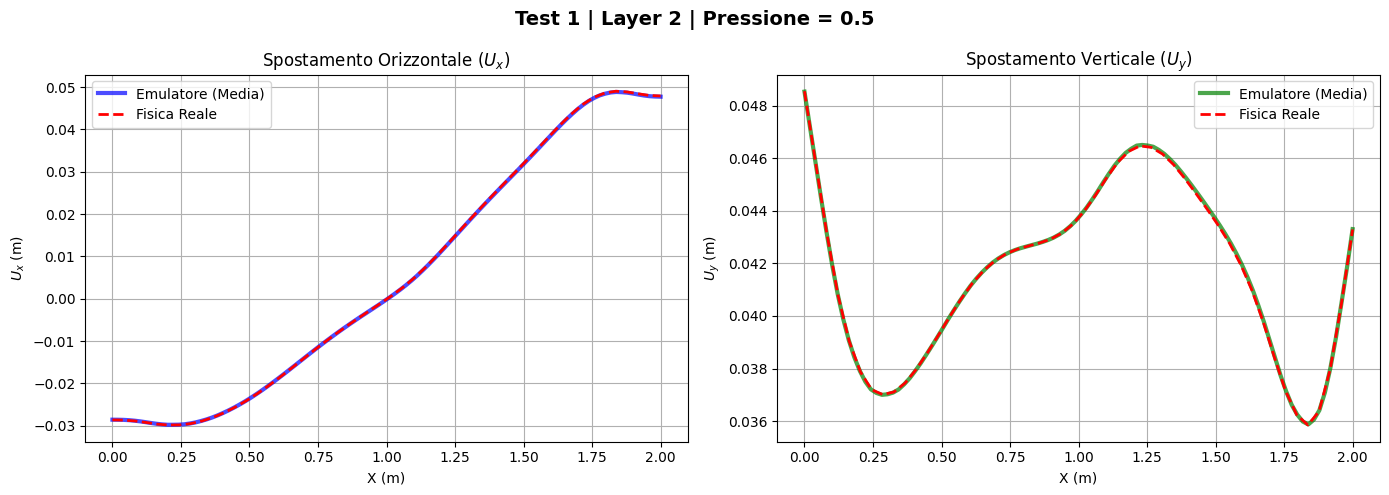


-----------------------------------------------------------------
🔹 TEST 2 | Layer: 1 | Pressione: -0.3
📍 Ground Truth campionato casualmente a: X=0.797, Y=0.511
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...


c:\Users\steto\anaconda3.1\envs\poresct4amm2526\Lib\site-packages\porepy\grids\mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")



📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: +5.3944e-03 | CI 90%: [+5.0618e-03, +6.4741e-03] -> ✅ PASSED
   Uy | Reale: -3.3172e-02 | CI 90%: [-3.6187e-02, -3.0258e-02] -> ✅ PASSED


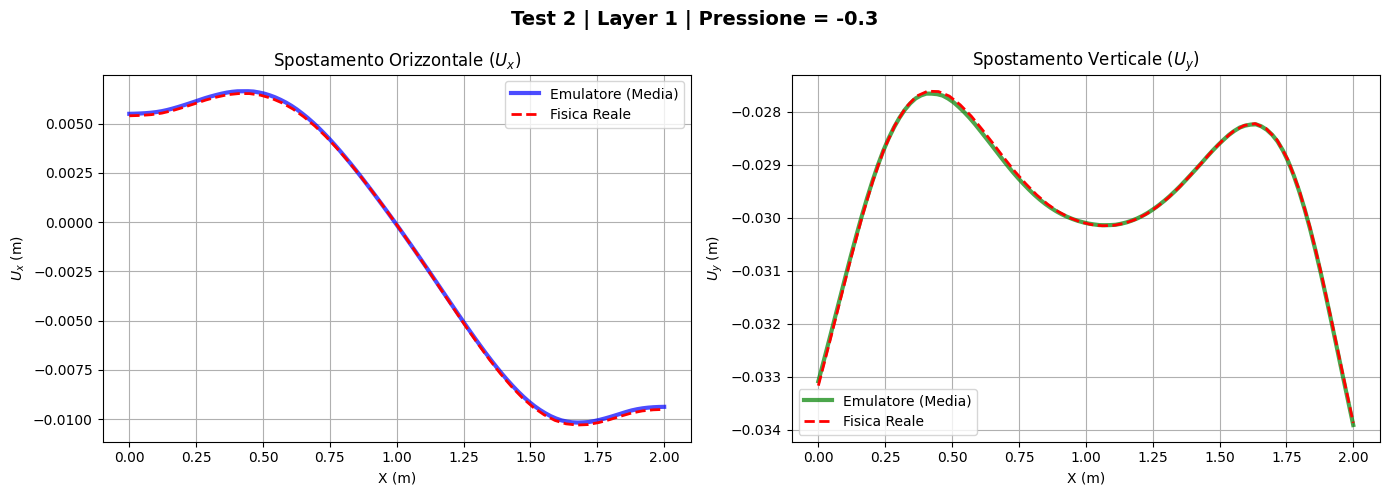


-----------------------------------------------------------------
🔹 TEST 3 | Layer: 3 | Pressione: 0.4
📍 Ground Truth campionato casualmente a: X=1.210, Y=0.405
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...


c:\Users\steto\anaconda3.1\envs\poresct4amm2526\Lib\site-packages\porepy\grids\mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")



📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: -1.0457e-01 | CI 90%: [-1.1331e-01, -9.5900e-02] -> ✅ PASSED
   Uy | Reale: -5.8703e-03 | CI 90%: [-6.6233e-03, -5.2170e-03] -> ✅ PASSED


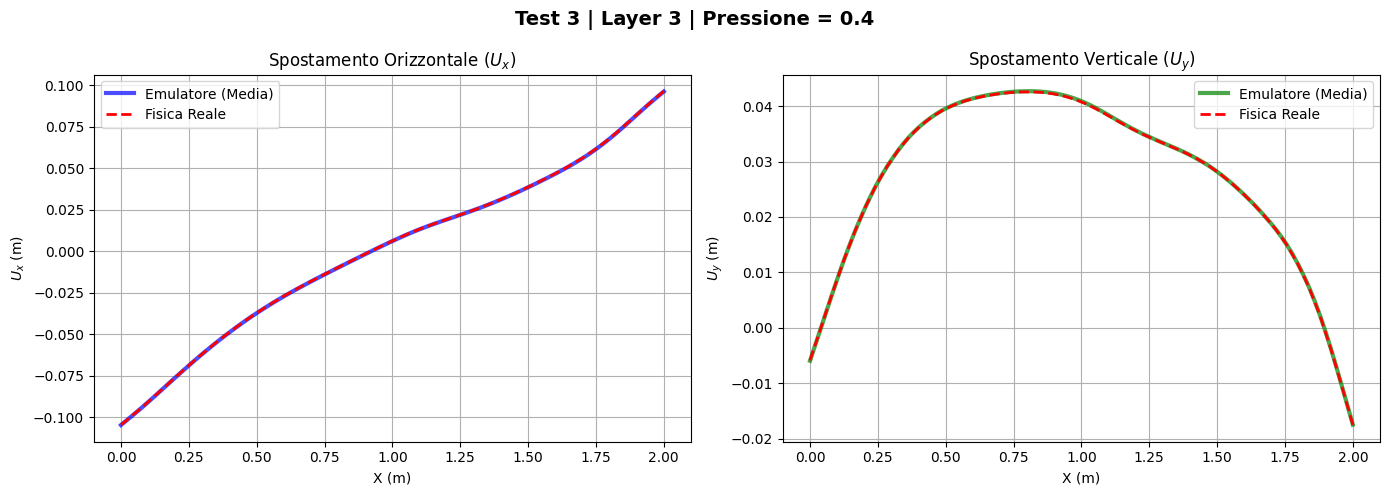


-----------------------------------------------------------------
🔹 TEST 4 | Layer: 2 | Pressione: -0.45
📍 Ground Truth campionato casualmente a: X=0.623, Y=0.611
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...


c:\Users\steto\anaconda3.1\envs\poresct4amm2526\Lib\site-packages\porepy\grids\mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")



📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: +2.4975e-02 | CI 90%: [+2.3273e-02, +2.7947e-02] -> ✅ PASSED
   Uy | Reale: -4.4128e-02 | CI 90%: [-4.9115e-02, -4.1219e-02] -> ✅ PASSED


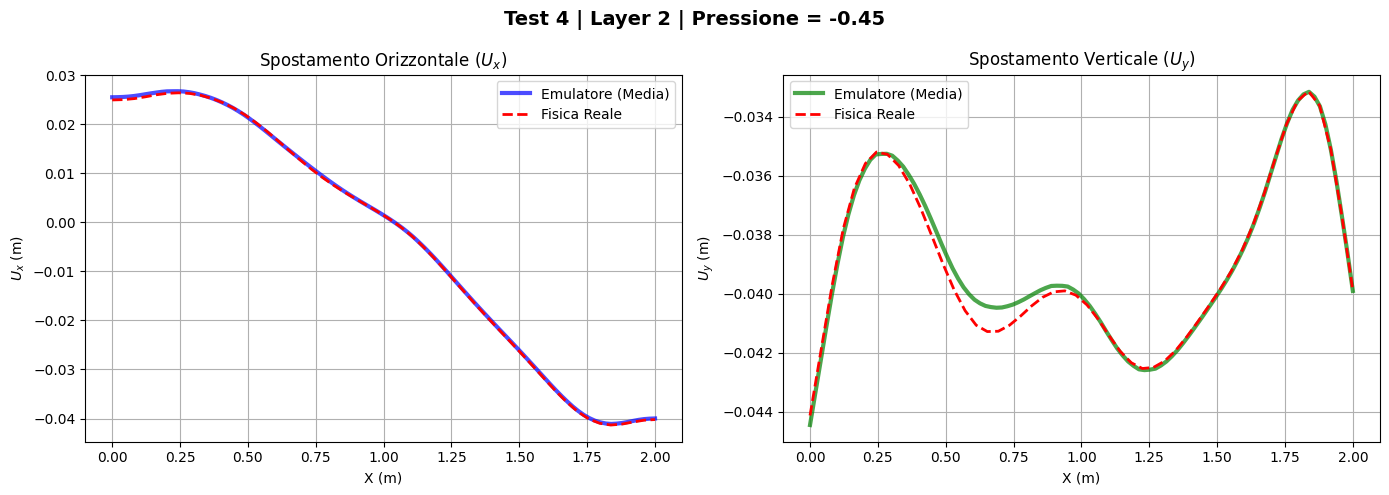


-----------------------------------------------------------------
🔹 TEST 5 | Layer: 0 | Pressione: 0.2
📍 Ground Truth campionato casualmente a: X=0.912, Y=0.410
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...


c:\Users\steto\anaconda3.1\envs\poresct4amm2526\Lib\site-packages\porepy\grids\mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")



📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: -4.4102e-03 | CI 90%: [-5.1122e-03, -4.0433e-03] -> ✅ PASSED
   Uy | Reale: +2.1880e-02 | CI 90%: [+1.9807e-02, +2.3628e-02] -> ✅ PASSED


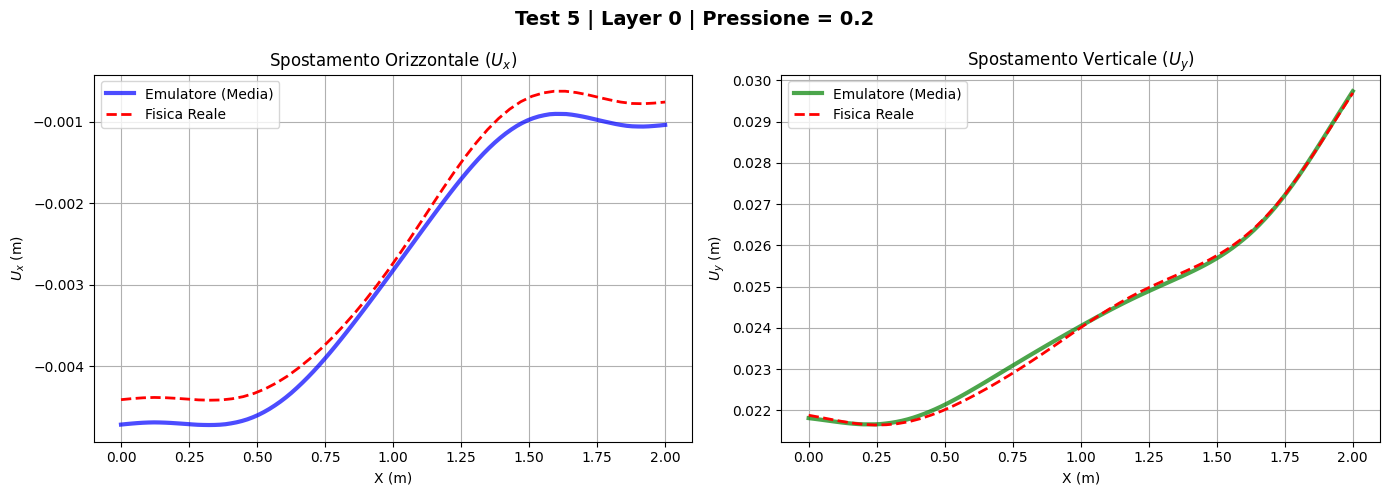

In [39]:
# =====================================================================
# 3. IL CICLO DI VALIDAZIONE
# =====================================================================
def run_cp2_validation():
    np.random.seed(42)
    
    test_cases = [
        {"id": 1, "layer": 3, "press":  0.50, "mu": (1.50, 0.25), "std": (0.045, 0.045)}, 
        {"id": 2, "layer": 2, "press": -0.30, "mu": (0.80, 0.50), "std": (0.015, 0.015)}, 
        {"id": 3, "layer": 4, "press":  0.40, "mu": (1.20, 0.35), "std": (0.030, 0.030)}, 
        {"id": 4, "layer": 3, "press": -0.45, "mu": (0.60, 0.60), "std": (0.020, 0.020)},
        {"id": 5, "layer": 1, "press":  0.20, "mu": (1.00, 0.40), "std": (0.040, 0.040)},
    ]
    
    print("="*65)
    print("🚀 AVVIO VALIDAZIONE INCROCIATA (EMULATORE vs FISICA REALE)")
    print("="*65)
    
    for tc in test_cases:
        # Correzione: Python conta da 0. Se il layer del compagno è "4", significa il layer index 3
        layer_idx = tc['layer'] - 1 if tc['layer'] > 0 else 0 

        print(f"\n" + "-"*65)
        print(f"🔹 TEST {tc['id']} | Layer: {layer_idx} | Pressione: {tc['press']}")
        
        true_cx = np.random.normal(tc['mu'][0], tc['std'][0])
        true_cy = np.random.normal(tc['mu'][1], tc['std'][1])
        print(f"📍 Ground Truth campionato casualmente a: X={true_cx:.3f}, Y={true_cy:.3f}")
        
        print("⏳ Calcolo FEM Ground Truth in corso (alta precisione)...")
        gt_ux_surf, gt_uy_surf, gt_ux_c, gt_uy_c = get_ground_truth(true_cx, true_cy, layer_idx, tc['press'])
        
        if gt_ux_surf is None:
            print("Saltato a causa di un crash FEM.")
            continue

        mean_surf_func, CI_corner = GroupSolutionCP2(
            layer_ID=layer_idx, 
            pressure_value=tc['press'], 
            center_location_mean=tc['mu'], 
            center_location_std=tc['std']
        )
        
        ci_ux = CI_corner[0]
        ci_uy = CI_corner[1]
        
        pass_ux = ci_ux[0] <= gt_ux_c <= ci_ux[1]
        pass_uy = ci_uy[0] <= gt_uy_c <= ci_uy[1]
        
        status_ux = "✅ PASSED" if pass_ux else "❌ FAILED"
        status_uy = "✅ PASSED" if pass_uy else "❌ FAILED"
        
        print("\n📊 ESITO VALIDAZIONE ANGOLO (0,1):")
        print(f"   Ux | Reale: {gt_ux_c:+.4e} | CI 90%: [{ci_ux[0]:+.4e}, {ci_ux[1]:+.4e}] -> {status_ux}")
        print(f"   Uy | Reale: {gt_uy_c:+.4e} | CI 90%: [{ci_uy[0]:+.4e}, {ci_uy[1]:+.4e}] -> {status_uy}")
        
        # PLOT
        x_plot = np.linspace(0.0, 2.0, 100)
        x_eval = np.linspace(0.0, 2.0, 50)
        
        ux_pred = [mean_surf_func(xi)[0] for xi in x_plot]
        uy_pred = [mean_surf_func(xi)[1] for xi in x_plot]
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f"Test {tc['id']} | Layer {layer_idx} | Pressione = {tc['press']}", fontsize=14, fontweight='bold')
        
        axes[0].plot(x_plot, ux_pred, 'b-', linewidth=3, alpha=0.7, label="Emulatore (Media)")
        axes[0].plot(x_eval, gt_ux_surf, 'r--', linewidth=2, label="Fisica Reale")
        axes[0].set_title("Spostamento Orizzontale ($U_x$)")
        axes[0].set_xlabel("X (m)")
        axes[0].set_ylabel("$U_x$ (m)")
        axes[0].grid(True)
        axes[0].legend()
        
        axes[1].plot(x_plot, uy_pred, 'g-', linewidth=3, alpha=0.7, label="Emulatore (Media)")
        axes[1].plot(x_eval, gt_uy_surf, 'r--', linewidth=2, label="Fisica Reale")
        axes[1].set_title("Spostamento Verticale ($U_y$)")
        axes[1].set_xlabel("X (m)")
        axes[1].set_ylabel("$U_y$ (m)")
        axes[1].grid(True)
        axes[1].legend()
        
        plt.tight_layout()
        plt.show()

if __name__ == '__main__':
    import multiprocessing as mp
    try:
        mp.set_start_method('spawn', force=True)
    except RuntimeError:
        pass
        
    run_cp2_validation()